In [1]:
from pathlib import Path
import inspect
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
import astro_prost.helpers as prost_helpers

from astro_prost import associate_sample
from scipy.stats import gamma, uniform

# Patch para compatibilidad con arreglos de solo lectura si es necesario
if not getattr(prost_helpers, "_shape_r_copy_patch_applied", False):
    source = textwrap.dedent(inspect.getsource(prost_helpers.calc_shape_props_decals))
    old = 'candidate_hosts["shape_r"].values'
    new = 'candidate_hosts["shape_r"].to_numpy(copy=True)'
    if old in source:
        exec(compile(source.replace(old, new), "<prost_notebook_patch>", "exec"),
             prost_helpers.__dict__)
    prost_helpers._shape_r_copy_patch_applied = True

# 1. Cargar catálogo completo desde la carpeta Result
parquet_path = Path("Result/snia_results.parquet")
if not parquet_path.exists():
    parquet_path = Path("notebooks/Result/snia_results.parquet")

transient_catalog = pd.read_parquet(parquet_path)
transient_catalog["name"] = transient_catalog["tns_name"].fillna(
    transient_catalog["diaObjectId"].astype(str)
)

# 2. Configurar catálogos (decals, panstarrs, skymapper) y priors
catalogs = ["decals", "panstarrs", "skymapper"]
priors = {"offset": uniform(loc=0, scale=10)}
likes = {"offset": gamma(a=0.75)}

# 3. Asociar todo el catálogo en paralelo
hosts = associate_sample(
    transient_catalog,
    priors=priors,
    likes=likes,
    catalogs=catalogs,
    name_col="name",
    coord_cols=("ra", "decl"),
    parallel=True,
    save=False,
)
print(f"Asociación completada: {len(hosts)} filas procesadas.")


2026-10-14 11:28:39,447- INFO - Conditioning association on the following properties: ['offset']


2026-10-14 11:28:42,211- INFO - Loaded GLADE+ catalog.


2026-10-14 11:28:42,213- INFO - WARNING! n_processes > 12. Dropping down.


2026-10-14 11:28:42,213- INFO - Parallelizing 57 associations across 12 processes.


2026-10-14 11:28:42,214- INFO - Processing batch 1/6 with 10 events.


...

2026-10-14 11:30:43,015- INFO - 
    
Properties of best host (in panstarrs dr2) for 2026nac:
    objID: 81792990137559223
    R.A. (deg): 299.013725
    Dec. (deg): -21.834222
    Posterior: 9.9130e-01
    Redshift: 0.0000 ± 0.0000
    Absolute Magnitude: 0.0 ± 0.0
    Transient Offset: 0.4 ± 0.1 arcsec
    Transient Offset Posterior: 9.9130e-01


2026-10-14 11:30:43,017- INFO - 
    
Properties of 2nd best host (in panstarrs dr2) for 2026nac:
    objID: 81712989857640072
    R.A. (deg): 298.985757
    Dec. (deg): -21.908587
    Posterior: 0.0000e+00
    Redshift: 0.0000 ± 0.0000
    Absolute Magnitude: 0.0 ± 0.0
    Transient Offset: 283.2 ± 0.1 arcsec
    Transient Offset Posterior: 0.0000e+00


2026-10-14 11:30:43,018- INFO - Chosen galaxy has catalog ID of 81792990137559223 and RA, DEC = 299.013725, -21.834222


2026-10-14 11:30:43,198- INFO - All associations succeeded; no more retries needed.


Asociación completada: 57 filas procesadas.


In [2]:
# --- Clasificar el resultado e identificar el catálogo de origen del host ---
CAT_LABELS = {
    "decals": "DECaLS",
    "panstarrs": "Pan-STARRS",
    "skymapper": "SkyMapper",
    "glade": "GLADE+",
}

def clasificar_origen(row):
    if row.get("_merge") == "left_only":
        return "Error / no procesado"
    if pd.isna(row.get("ra")) or pd.isna(row.get("decl")):
        return "Error / no procesado"
    if pd.notna(row.get("host_ra")):
        cat_key = str(row.get("best_cat", "")).strip().lower()
        cat_name = CAT_LABELS.get(cat_key, cat_key.upper() if cat_key else "Desconocido")
        return f"Host ({cat_name})"
    return "Sin host"

out_cols = [c for c in ["name", "best_cat", "best_cat_release", "host_objID", "host_name", "host_ra", "host_dec", "host_redshift_mean", "host_total_posterior", "host_offset_mean"] if c in hosts.columns]

reporte = transient_catalog[["diaObjectId", "tns_name", "name", "ra", "decl"]].merge(
    hosts[out_cols].drop_duplicates(subset=["name"]),
    on="name", how="left", indicator=True,
)
reporte["origen_host"] = reporte.apply(clasificar_origen, axis=1)
reporte = reporte.drop(columns="_merge")
reporte.insert(0, "n", range(1, len(reporte) + 1))

display(reporte.head(10))


,n,diaObjectId,tns_name,name,ra,decl,best_cat,best_cat_release,host_objID,host_name,host_ra,host_dec,host_redshift_mean,host_total_posterior,host_offset_mean,origen_host
0,1,170028521695477812,2025aluu,2025aluu,151.317670,2.395216,decals,dr9,9906622400627967,,151.317465,2.394184,0.093312,1.000000,3.782406,Host (DECaLS)
1,2,170028526740701203,2026fca,2026fca,186.910112,8.014847,decals,dr9,9906624478512957,,186.910232,8.014085,0.065415,0.678448,2.772723,Host (DECaLS)
2,3,170028527145975899,2026fkf,2026fkf,187.084150,8.366138,decals,dr9,9906624572096840,,187.083854,8.366365,0.168517,1.000000,1.338894,Host (DECaLS)
3,4,170028527544959074,2025hlf,2025hlf,185.988512,8.763230,decals,dr9,9906624758615935,,185.988976,8.762566,0.073115,0.999250,2.901744,Host (DECaLS)
4,5,170032908006326285,2022and,2022and,150.027554,3.757143,decals,dr9,9906622871832177,,150.027762,3.756884,0.039972,0.710103,1.195946,Host (DECaLS)
5,6,170032916211957834,2022hss,2022hss,186.409958,7.192500,decals,dr9,9906624197429850,,186.408625,7.192303,0.025106,0.407449,4.810513,Host (DECaLS)
6,7,170046109144055918,2022hss,2022hss,186.409958,7.192500,decals,dr9,9906624197429850,,186.408625,7.192303,0.025106,0.407449,4.810513,Host (DECaLS)
7,8,170046109287710745,2026fkf,2026fkf,187.084150,8.366138,decals,dr9,9906624572096840,,187.083854,8.366365,0.168517,1.000000,1.338894,Host (DECaLS)
8,9,170046109948313615,2022hss,2022hss,186.409958,7.192500,decals,dr9,9906624197429850,,186.408625,7.192303,0.025106,0.407449,4.810513,Host (DECaLS)
9,10,170046114785919044,2026fca,2026fca,186.910112,8.014847,decals,dr9,9906624478512957,,186.910232,8.014085,0.065415,0.678448,2.772723,Host (DECaLS)


Resumen por catálogo de origen:
origen_host
Host (DECaLS)        41
Host (Pan-STARRS)    16
Total: 57


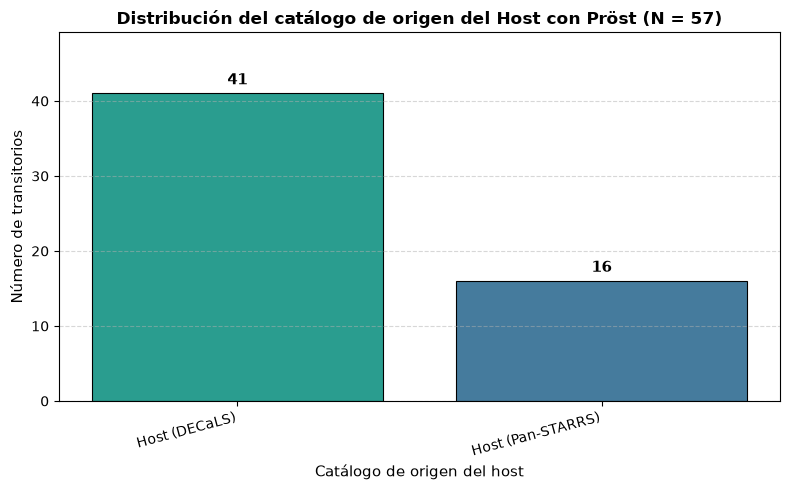

In [3]:
# --- Resumen y gráfica con el catálogo de procedencia del host ---
conteo = reporte["origen_host"].value_counts()

orden_preferido = ["Host (DECaLS)", "Host (Pan-STARRS)", "Host (SkyMapper)", "Host (GLADE+)", "Sin host", "Error / no procesado"]
categorias = [cat for cat in orden_preferido if cat in conteo.index] + [c for c in conteo.index if c not in orden_preferido]
conteo = conteo.reindex(categorias, fill_value=0)

print("Resumen por catálogo de origen:")
print(conteo.to_string())
print(f"Total: {conteo.sum()}")

color_map = {
    "Host (DECaLS)": "#2a9d8f",
    "Host (Pan-STARRS)": "#457b9d",
    "Host (SkyMapper)": "#9b5de5",
    "Host (GLADE+)": "#1d3557",
    "Sin host": "#e9c46a",
    "Error / no procesado": "#e76f51"
}
colores = [color_map.get(cat, "#6c757d") for cat in conteo.index]

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(conteo.index, conteo.values, color=colores, edgecolor="black", linewidth=0.8)
ax.bar_label(barras, padding=4, fontsize=11, fontweight="bold")
ax.set_ylabel("Número de transitorios", fontsize=11)
ax.set_xlabel("Catálogo de origen del host", fontsize=11)
ax.set_title(f"Distribución del catálogo de origen del Host con Pröst (N = {len(reporte)})", fontsize=12, fontweight="bold")
ax.set_ylim(0, conteo.max() * 1.15 + 2)
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=15, ha="right", fontsize=10)
plt.tight_layout()
plt.show()


In [4]:
# --- Guardar catálogo completo con la información nueva del host en formato Parquet ---
# Excluir columnas con diccionarios vacíos (extra_cat_cols) incompatibles con el esquema de Parquet
host_cols_new = [c for c in hosts.columns if c not in transient_catalog.columns and c != "extra_cat_cols"]
transients_with_hosts = transient_catalog.merge(
    hosts[["name"] + host_cols_new].drop_duplicates(subset=["name"]),
    on="name",
    how="left"
)
transients_with_hosts["origen_host"] = reporte["origen_host"].values

output_parquet = parquet_path.parent / "snia_results_with_hosts.parquet"
transients_with_hosts.to_parquet(output_parquet, index=False)
print(f"Resultados guardados exitosamente en:\n  -> {output_parquet}")
print(f"Dimensiones del archivo guardado: {transients_with_hosts.shape[0]} filas x {transients_with_hosts.shape[1]} columnas")


Resultados guardados exitosamente en:
  -> Result/snia_results_with_hosts.parquet
Dimensiones del archivo guardado: 57 filas x 50 columnas
